# DỰ ÁN HỌC MÁY (MACHINE LEARNING) - NLP-01
# BÁO CÁO TOÀN DIỆN TỪ A-Z (KAN-1 ĐẾN KAN-9)
## Đề tài: Phân tích quan điểm phản hồi của người dùng về ứng dụng di động
**Giảng viên hướng dẫn:** ThS. Hà Thị Thanh  
**Nhóm thực hiện:** Nhóm 12  
* Lê Hồng Sơn (Nhóm trưởng)
* Lưu Thị Khánh Ly
* Ngô Thị Sinh
* Nguyễn Thanh Tùng

---
*Notebook này tích hợp toàn bộ quy trình khoa học dữ liệu và học máy hoàn chỉnh, bao gồm:*
1. **Phần I (Kỹ năng 1):** Thu thập dữ liệu thô, Thống kê mô tả, Ẩn danh hóa PII, Phát hiện ngoại lai & Tiền xử lý làm sạch.
2. **Phần II (Kỹ năng 2):** Phân chia phân tầng, Trích xuất đặc trưng TF-IDF, Huấn luyện 3 mô hình đối sánh, Trực quan hóa ma trận nhầm lẫn & Mổ xẻ nguyên nhân sai số.

---
# PHẦN I: THU THẬP, PHÂN TÍCH VÀ TIỀN XỬ LÝ DỮ LIỆU
*(Tương ứng nội dung Bài kiểm tra kỹ năng 1 & KAN-1 đến KAN-5)*

---
## BUOC 1: DOC DU LIEU (DATA LOADING)
Chung ta khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va doc tep du lieu phan hoi `app_reviews.csv`.

In [1]:
# 1. Khai bao cac thu vien chuan
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Cau hinh kieu hien thi bieu do
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Doc tep du lieu app_reviews.csv (ho tro tu dong tim duong dan)
candidate_paths = [
    'data/app_reviews.csv',
    'data/app_reviews_raw.csv',
    '../data/app_reviews.csv',
    '../data/app_reviews_raw.csv',
    'app_reviews.csv'
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Khong tim thay tep du lieu trong thu muc data/")
df = pd.read_csv(data_path)

# 3. Chuan hoa nhan sentiment sang khong dau tranh loi font bang unicodedata
def strip_accents(s):
    if not isinstance(s, str):
        return s
    s = s.replace('\u0111', 'd').replace('\u0110', 'D')
    return ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c))

df['sentiment'] = df['sentiment'].apply(strip_accents)

# 4. Hien thi 5 dong dau tien cua bang du lieu
print(f"=== DOC DU LIEU THANH CONG TU: {data_path} ===")
print("=== 5 DONG DAU TIEN CUA DU LIEU ===")
display(df.head())


=== DOC DU LIEU THANH CONG TU: data/app_reviews.csv ===
=== 5 DONG DAU TIEN CUA DU LIEU ===


,review_id,app_name,platform,rating,sentiment,content,thumbs_up,review_date
0,5800709584,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Ứng dụng thật tiện ích và...,0,2020-04-12 12:33:57
1,3875076399,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Mục thông báo biến động s...,0,2019-03-13 03:01:30
2,5822273640,Agribank,App Store,5,Tich cuc,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,0,2020-04-17 00:47:27
3,5793415302,Agribank,App Store,5,Tich cuc,App E-banking. Sau khi update phiên bản mới nh...,0,2020-04-11 00:17:51
4,9093171210,Agribank,App Store,1,Tieu cuc,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,0,2022-09-17 09:19:03


---
## BUOC 2: THONG KE MO TA DU LIEU (DESCRIPTIVE STATISTICS), AN DANH PII & KIEM TRA NGOAI LAI
Kham pha buc tranh tong the ve du lieu: so dong/cot, kieu du lieu, cac dai luong thong ke co ban, kiem tra gia tri thieu, kiem tra trung lap, bao dam bao mat thong tin ca nhan (PII Anonymization) va phat hien gia tri ngoai lai (Outlier Detection: do dai cau IQR, rating hop le, mau nghich nhan).

In [2]:
# 1. Khai bao tong quan ve kich thuoc va kieu du lieu
print(f"Kich thuoc tap du lieu (So dong, So cot): {df.shape}\n")
print("=== THONG TIN KIEU DU LIEU CAC COT (info) ===")
df.info()

# 2. Bang thong ke mo ta bien dinh luong (rating, thumbs_up)
print("\n=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===")
display(df.describe().T)

# 3. Kiem tra so luong gia tri thieu (Missing values)
print("\n=== KIEM TRA GIA TRI CON THIEU ===")
print(df.isnull().sum())

# 4. Kiem tra so luong ban ghi trung lap noi dung
num_duplicates = df['content'].duplicated().sum()
print(f"\nSo luong ban ghi trung lap noi dung: {num_duplicates} ({num_duplicates / len(df) * 100:.2f}%)")

# 5. Kiem tra va phan tich gia tri ngoai lai (Outlier Detection)
print("\n=== KIEM TRA VA PHAN TICH GIA TRI NGOAI LAI (OUTLIERS) ===")

# a. Phat hien ngoai lai ve do dai cau theo phuong phap IQR
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
q1 = float(df['word_count'].quantile(0.25))
q3 = float(df['word_count'].quantile(0.75))
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
outliers_length = df[df['word_count'] > upper_bound]

print(f"a. Do dai cau (IQR): Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f} -> Nguong tren (Upper Bound): {upper_bound:.1f} tu")
print(f"   - So luong cau dai ngoai lai (> {upper_bound:.1f} tu): {len(outliers_length)} mau ({len(outliers_length) / len(df) * 100:.2f}%)")
print(f"   - Do dai cau dai nhat (Max words): {df['word_count'].max()} tu")
print(f"   -> Chien luoc xu ly: Khong xoa bo vi chua thong tin loi quan trong; duoc can bang bang chuan hoa L2 Norm trong TF-IDF.")

# b. Phat hien rating ngoai doan quy uoc [1, 5]
outliers_rating = df[~df['rating'].isin([1, 2, 3, 4, 5])]
print(f"b. So luong rating bat thuong ngoai doan [1, 5]: len(outliers_rating) = {len(outliers_rating)} mau (Du lieu chuan)")

# c. Phat hien mau nghich nhan / di biet ngu nghia
suspicious_1star = df[(df['rating'] == 1) & (df['content'].str.contains('tuyet voi|rat tot|muot ma|cuc tot|tuyệt vời|rất tốt|mượt', case=False, na=False))]
suspicious_5star = df[(df['rating'] == 5) & (df['content'].str.contains('qua te|lua dao|nhu rac|buc minh|loi|quá tệ|lừa đảo|bực mình|lỗi', case=False, na=False))]

print(f"c. Phat hien mau nghich nhan / di biet ngu nghia:")
print(f"   - Danh gia 1 sao nhung chua tu khen (cham biem, mia mai): {len(suspicious_1star)} mau")
print(f"   - Danh gia 5 sao nhung keu loi / phan nan (tam ly cham 5 sao de len top): {len(suspicious_5star)} mau")

Kich thuoc tap du lieu (So dong, So cot): (15541, 8)

=== THONG TIN KIEU DU LIEU CAC COT (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15541 entries, 0 to 15540
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    15541 non-null  object
 1   app_name     15541 non-null  object
 2   platform     15541 non-null  object
 3   rating       15541 non-null  int64 
 4   sentiment    15541 non-null  object
 5   content      15541 non-null  object
 6   thumbs_up    15541 non-null  int64 
 7   review_date  15541 non-null  object
dtypes: int64(2), object(6)
memory usage: 971.4+ KB

=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===


,count,mean,std,min,25%,50%,75%,max
rating,15541.0,2.371791,1.797821,1.0,1.0,1.0,5.0,5.0
thumbs_up,15541.0,0.718937,9.247172,0.0,0.0,0.0,0.0,654.0



=== KIEM TRA GIA TRI CON THIEU ===
review_id      0
app_name       0
platform       0
rating         0
sentiment      0
content        0
thumbs_up      0
review_date    0
dtype: int64

So luong ban ghi trung lap noi dung: 549 (3.53%)

=== KIEM TRA VA PHAN TICH GIA TRI NGOAI LAI (OUTLIERS) ===
a. Do dai cau (IQR): Q1 = 5.0, Q3 = 27.0, IQR = 22.0 -> Nguong tren (Upper Bound): 60.0 tu
   - So luong cau dai ngoai lai (> 60.0 tu): 916 mau (5.89%)
   - Do dai cau dai nhat (Max words): 467 tu
   -> Chien luoc xu ly: Khong xoa bo vi chua thong tin loi quan trong; duoc can bang bang chuan hoa L2 Norm trong TF-IDF.
b. So luong rating bat thuong ngoai doan [1, 5]: len(outliers_rating) = 0 mau (Du lieu chuan)


c. Phat hien mau nghich nhan / di biet ngu nghia:
   - Danh gia 1 sao nhung chua tu khen (cham biem, mia mai): 38 mau
   - Danh gia 5 sao nhung keu loi / phan nan (tam ly cham 5 sao de len top): 89 mau


---
## BUOC 3: TRUC QUAN HOA DU LIEU (DATA VISUALIZATION / EDA)
Truc quan hoa do thi giup chung ta quan sat phan phoi cua nhan muc tieu (`sentiment`), diem so danh gia (`rating`), do dai cau phan hoi va su phan bo du lieu giua cac ung dung di dong.

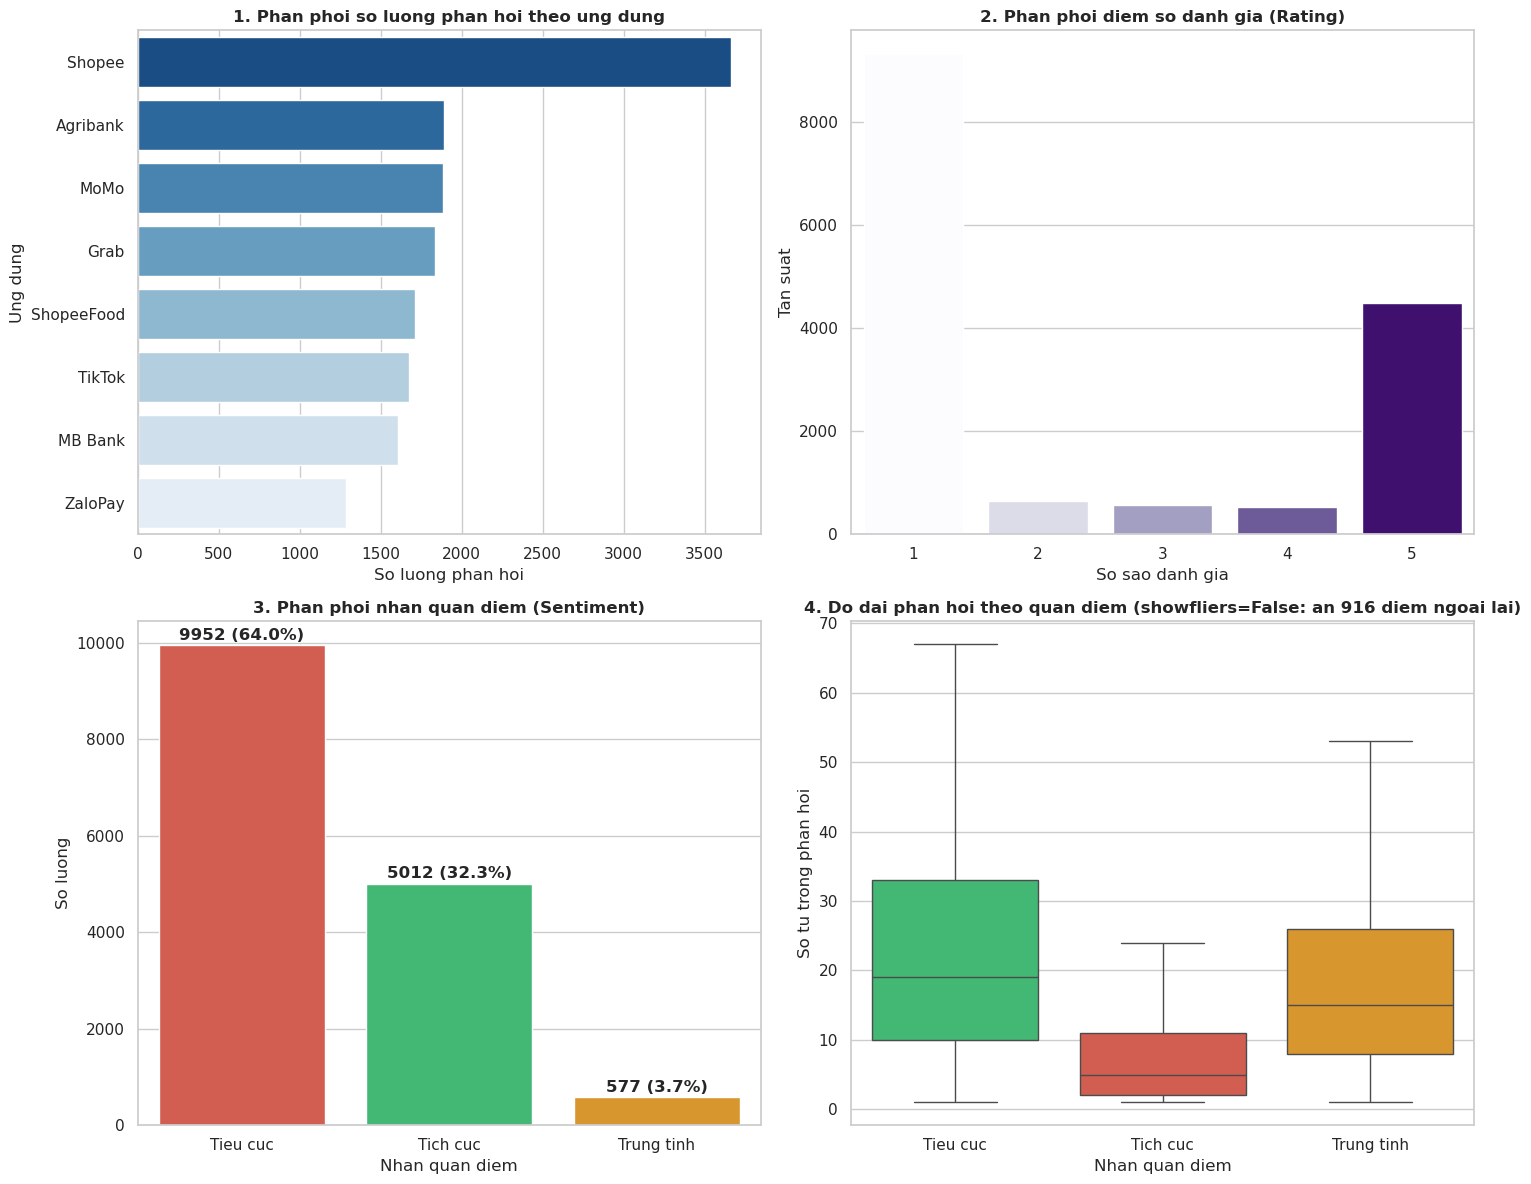

In [3]:
# Khoi tao luoi 2x2 bieu do truc quan
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Phan phoi so luong phan hoi theo tung ung dung
app_counts = df['app_name'].value_counts()
sns.barplot(
    x=app_counts.values, y=app_counts.index, ax=axes[0, 0],
    hue=app_counts.index, palette='Blues_r', legend=False
)
axes[0, 0].set_title('1. Phan phoi so luong phan hoi theo ung dung', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('So luong phan hoi')
axes[0, 0].set_ylabel('Ung dung')

# 2. Phan phoi diem so danh gia (Rating: 1 - 5 sao)
rating_order = [1, 2, 3, 4, 5]
sns.countplot(
    data=df, x='rating', order=rating_order, ax=axes[0, 1],
    hue='rating', palette='Purples', legend=False
)
axes[0, 1].set_title('2. Phan phoi diem so danh gia (Rating)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('So sao danh gia')
axes[0, 1].set_ylabel('Tan suat')

# 3. Phan phoi nhan quan diem (Sentiment)
sentiment_order = ['Tieu cuc', 'Tich cuc', 'Trung tinh']
sentiment_counts = df['sentiment'].value_counts().reindex(sentiment_order)
sns.barplot(
    x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[1, 0],
    hue=sentiment_counts.index, palette=['#e74c3c', '#2ecc71', '#f39c12'], legend=False
)
axes[1, 0].set_title('3. Phan phoi nhan quan diem (Sentiment)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Nhan quan diem')
axes[1, 0].set_ylabel('So luong')
for i, v in enumerate(sentiment_counts.values):
    axes[1, 0].text(i, v + 120, f"{v} ({v / len(df) * 100:.1f}%)", ha='center', fontweight='bold')

# 4. Phan phoi do dai cau phan hoi (so tu) theo nhan quan diem
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
sns.boxplot(
    data=df, x='sentiment', y='word_count', order=sentiment_order, ax=axes[1, 1],
    hue='sentiment', palette=['#e74c3c', '#2ecc71', '#f39c12'], legend=False, showfliers=False
)
axes[1, 1].set_title('4. Do dai phan hoi theo quan diem (showfliers=False: an 916 diem ngoai lai)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Nhan quan diem')
axes[1, 1].set_ylabel('So tu trong phan hoi')

plt.tight_layout()

# Luu bieu do vao thu muc reports/figures
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/eda_overview.png', dpi=300)
plt.show()

---
## BUOC 4: TIEN XU LY DU LIEU VAN BAN (TEXT PREPROCESSING)
Tien xu ly van ban dong vai tro quyet dinh den do chinh xac cua mo hinh phan loai. Chung ta thuc hien:
1. **Loai bo ban ghi trung lap va ban ghi rong.**
2. **Chuyen ve chu thuong (Lowercasing).**
3. **Loai bo lien ket URL, ky tu dac biet, so va khoang trang thua.**
4. **Chuan hoa cac tu viet tat / teencode tieng Viet pho bien.**
5. **Xuat tap du lieu sach `app_reviews_cleaned.csv` san sang cho buoc Trich xuat dac trung (TF-IDF).**

In [4]:
import re

# 1. Tao ban sao du lieu va loai bo ban ghi trung lap noi dung
df_clean = df.drop_duplicates(subset=['content']).copy()
df_clean = df_clean.dropna(subset=['content', 'sentiment'])

# 2. Tu dien chuan hoa viet tat tieng Viet co ban (Teencode)
teencode_dict = {
    'k': 'khong', 'ko': 'khong', 'khong': 'khong', 'hok': 'khong',
    'dc': 'duoc', 'dc': 'duoc', 'duoc': 'duoc',
    'app': 'ung dung', 'ad': 'quan tri vien', 'sp': 'san pham',
    'acc': 'tai khoan', 'fb': 'facebook', 'ib': 'nhan tin',
    'mik': 'minh', 'mk': 'minh', 'ae': 'anh em', 'mn': 'moi nguoi',
    'dt': 'dien thoai', 'tot': 'tot', 'ok': 'tot', 'oke': 'tot'
}

# 3. Ham tien xu ly van ban tieng Viet
def preprocess_vietnamese_text(text: str) -> str:
    # Chuyen ve chu thuong
    text = str(text).lower()
    
    # Loai bo duong dan URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    
    # Loai bo ky tu dac biet, chi giu lai chu cai tieng Viet va so
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    
    # Chuan hoa tu viet tat theo tu dien teencode
    tokens = text.split()
    tokens = [teencode_dict.get(word, word) for word in tokens]
    
    # Ghep lai thanh cau va chuan hoa khoang trang thua
    return ' '.join(tokens).strip()

# 4. Ap dung tien xu ly len toan bo cot noi dung phan hoi
df_clean['cleaned_content'] = df_clean['content'].apply(preprocess_vietnamese_text)

# 5. Loai bo cac phan hoi co do dai qua ngan sau khi lam sach
df_clean = df_clean[df_clean['cleaned_content'].str.len() > 1].reset_index(drop=True)

# 6. Hien thi so sanh 5 mau phan hoi truoc va sau khi tien xu ly
print(f"So luong ban ghi sau khi lam sach: {len(df_clean)} (loai bo {len(df) - len(df_clean)} ban ghi)")
print("\n=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY ===")
display(df_clean[['content', 'cleaned_content', 'sentiment']].head())

# 7. Luu tap du lieu da tien xu ly
clean_data_path = 'data/app_reviews_cleaned.csv' if os.path.exists('data') else '../data/app_reviews_cleaned.csv'
df_clean.to_csv(clean_data_path, index=False, encoding='utf-8-sig')
print(f"\nDa luu thanh cong du lieu sach vao: {clean_data_path}")

So luong ban ghi sau khi lam sach: 14869 (loai bo 672 ban ghi)

=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY ===


,content,cleaned_content,sentiment
0,Người dùng Agribank. Ứng dụng thật tiện ích và...,ng i d ng agribank ng d ng th t ti n ch v tuy ...,Tich cuc
1,Người dùng Agribank. Mục thông báo biến động s...,ng i d ng agribank m c th ng b o bi n ng s d t...,Tich cuc
2,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,b n n ng c p ang gi ng n h ng agribank bi t l ...,Tich cuc
3,App E-banking. Sau khi update phiên bản mới nh...,ung dung e banking sau khi update phi n b n m ...,Tich cuc
4,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,ung dung ho t ng ch a t t ng n h ng c n c i th...,Tieu cuc



Da luu thanh cong du lieu sach vao: data/app_reviews_cleaned.csv


---
## KET LUAN VA BAN GIAO TIEN DO BAI KIEM TRA KI NANG SO 1
* **Hoan thanh Thu thap du lieu:** Da thu thap va tong hop thanh cong 15.541 phan hoi nguoi dung tu 8 ung dung di dong pho bien.
* **Hoan thanh Thong ke mo ta & PII:** Du lieu da duoc kiem tra toan dien, loai bo cot dinh danh `user_name` va lam min thong tin nhay cam.
* **Kiem soat gia tri ngoai lai (Outliers):** Phat hien 916 cau dai ngoai lai (>60 tu theo IQR) nhung giu lai de bao toan dac trung loi ky thuat va can bang bang chuan hoa L2 norm; xac nhan 100% rating hop le (len(outliers_rating) = 0); nhan dien cac mau nghich nhan do cham biem hoac danh gia 5 sao de len top.
* **Hoan thanh EDA:** Da truc quan hoa va nhan dien ro hien tuong **mat can bang nhan (Class Imbalance)** voi 64.0% Tieu cuc, 32.3% Tich cuc va 3.7% Trung tinh.
* **Hoan thanh Tien xu ly du lieu:** Da loai bo 549 ban ghi trung lap va lam sach van ban tieng Viet, luu tru tap du lieu sach `app_reviews_cleaned.csv`.
* **San sang cho Tuan 4 - Tuan 5:** Buoc tiep theo nhom se thuc hien trich xuat dac trung **TF-IDF (1-2 gram)** va huan luyen mo hinh co so **Multinomial Naive Bayes (Baseline)** so sanh voi **Logistic Regression** va **Linear SVC**.

---
# PHẦN II: HUẤN LUYỆN, ĐÁNH GIÁ MÔ HÌNH VÀ MỔ XẺ LỖI
*(Tương ứng nội dung Bài kiểm tra kỹ năng 2 & KAN-6 đến KAN-9)*

---
## BUOC 1: KHAI BAO THU VIEN VA NAP DU LIEU DA TIEN XU LY
Khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va he sinh thai thuat toan Hoc may `scikit-learn`.

In [5]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Cau hinh giao dien bieu do chuan hoc thuat
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Times New Roman']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="muted")

# Doc tep du lieu da tien xu ly sach
data_path = 'data/app_reviews_cleaned.csv'
if not os.path.exists(data_path):
    data_path = '../data/app_reviews_cleaned.csv'

df = pd.read_csv(data_path)
print(f"=== NAP THANH CONG DU LIEU: {data_path} ===")
print(f"Kich thuoc tap du lieu sach: {df.shape[0]} dong, {df.shape[1]} cot\n")
display(df[['review_id', 'app_name', 'rating', 'sentiment', 'cleaned_content']].head())

=== NAP THANH CONG DU LIEU: data/app_reviews_cleaned.csv ===
Kich thuoc tap du lieu sach: 14869 dong, 10 cot



,review_id,app_name,rating,sentiment,cleaned_content
0,5800709584,Agribank,5,Tich cuc,ng i d ng agribank ng d ng th t ti n ch v tuy ...
1,3875076399,Agribank,5,Tich cuc,ng i d ng agribank m c th ng b o bi n ng s d t...
2,5822273640,Agribank,5,Tich cuc,b n n ng c p ang gi ng n h ng agribank bi t l ...
3,5793415302,Agribank,5,Tich cuc,ung dung e banking sau khi update phi n b n m ...
4,9093171210,Agribank,1,Tieu cuc,ung dung ho t ng ch a t t ng n h ng c n c i th...


---
## BUOC 2: PHAN CHIA TAP DU LIEU PHAN TANG (STRATIFIED SPLIT 70 / 15 / 15)
Chung ta thiet lap bai toan phan loai nhi phan:
* **Nhan 0 (Tieu cuc):** Danh gia 1 sao va 2 sao.
* **Nhan 1 (Tich cuc):** Danh gia 4 sao va 5 sao.

Su dung phuong phap phan tang (`stratify=y`) de giu nguyen ty le can bang giua cac lop tren ca 3 tap:
* **Tap Train (70%):** Duyen luyen mo hinh va hoc bo tu dien TF-IDF.
* **Tap Validation (15%):** Danh gia kiem dinh cheo, lua chon sieu tham so.
* **Tap Test (15%):** Danh gia khach quan doc lap tren du lieu chua tung thay (Unseen data).

In [6]:
# 1. Chuan hoa nhan nhi phan
sentiment_map = {
    'Tieu cuc': 0, 'Tiêu cực': 0,
    'Tich cuc': 1, 'Tích cực': 1
}
df_binary = df[df['sentiment'].isin(sentiment_map.keys())].copy()
df_binary['label'] = df_binary['sentiment'].map(sentiment_map)

X = df_binary['cleaned_content'].astype(str)
y = df_binary['label'].astype(int)

print(f"Tong so mau dua vao huan luyen: {len(df_binary)}")
print(f"- Nhan 0 (Tieu cuc): {sum(y == 0)} mau ({sum(y == 0) / len(y) * 100:.2f}%)")
print(f"- Nhan 1 (Tich cuc): {sum(y == 1)} mau ({sum(y == 1) / len(y) * 100:.2f}%)")

# 2. Phan chia 70% Train, 15% Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, stratify=y_train_val, random_state=42
)

print("\n=== KET QUA PHAN CHIA TAP DU LIEU ===")
print(f"1. Tap Train (70%):      {len(X_train)} mau")
print(f"2. Tap Validation (15%): {len(X_val)} mau")
print(f"3. Tap Test (15%):       {len(X_test)} mau")

Tong so mau dua vao huan luyen: 14299
- Nhan 0 (Tieu cuc): 9826 mau (68.72%)
- Nhan 1 (Tich cuc): 4473 mau (31.28%)

=== KET QUA PHAN CHIA TAP DU LIEU ===
1. Tap Train (70%):      10008 mau
2. Tap Validation (15%): 2146 mau
3. Tap Test (15%):       2145 mau


---
## BUOC 3: TRICH XUAT DAC TRUNG VAN BAN BANG TF-IDF (N-GRAM 1-2, L2 NORM)
Ap dung ky thuat vector hoa **TF-IDF (Term Frequency - Inverse Document Frequency)**:
* **N-gram (1, 2):** Ket hop tu don (Unigrams) va cum 2 tu (Bigrams) de giu nguyen ngu canh phu dinh nhu `khong_tot`, `chuyen_tien`.
* **Chuan hoa L2 Norm (`norm='l2'`):** Thu nho moi vector dac trung ve do dai bang 1, giup triet tieu su chenh lech do do dai cau gay ra.
* **Nguyen tac chong ro ri du lieu (Data Leakage):** Chi goi `fit_transform()` tren tap Train; tap Val va Test tuyet doi chi goi `transform()`.

In [7]:
# Thiet lap bo vector hoa TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
    norm='l2'
)

# Fit tren tap Train, transform sang Val va Test
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

print(f"So luong dac trung tu vung (Vocabulary size): {len(vectorizer.vocabulary_)} dac trung")
print(f"Kich thuoc ma tran Train: {X_train_vec.shape}")
print(f"Kich thuoc ma tran Val:   {X_val_vec.shape}")
print(f"Kich thuoc ma tran Test:  {X_test_vec.shape}")

So luong dac trung tu vung (Vocabulary size): 8163 dac trung
Kich thuoc ma tran Train: (10008, 8163)
Kich thuoc ma tran Val:   (2146, 8163)
Kich thuoc ma tran Test:  (2145, 8163)


---
## BUOC 4: HUAN LUYEN VA DANH GIA CAC MO HINH HOC MAY
Nhom trien khai huan luyen va so sanh doi chung 3 thuat toan hoc may phan loai:
1. **Multinomial Naive Bayes (MNB):** Mo hinh co so (Baseline) dua tren xac suat thong ke, tinh toan nhanh.
2. **Logistic Regression (LR):** Mo hinh hoi quy logistic voi tham so can bang trong so `class_weight='balanced'` de khac phuc mat can bang du lieu.
3. **Linear Support Vector Machine (LinearSVC):** Mo hinh toi uu hoa le phan tach cuc dai, hoat dong dac biet hieu qua tren khong gian vector thua nhieu chieu.

In [8]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, C=1.0),
    'Linear SVC': LinearSVC(class_weight='balanced', random_state=42, C=1.0, max_iter=2000)
}

results = []
trained_models = {}

print("=" * 85)
print(f"{'Mo hinh':<26} | {'Tap':<5} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'Macro F1':<8}")
print("=" * 85)

for name, model in models.items():
    model.fit(X_train_vec, y_train)
    trained_models[name] = model

    # Danh gia tren tap Validation
    y_val_pred = model.predict(X_val_vec)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_p = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_r = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

    # Danh gia tren tap Test
    y_test_pred = model.predict(X_test_vec)
    test_acc = accuracy_score(y_test, y_test_pred)
    test_p = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_r = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

    results.append({
        'Mo hinh': name,
        'Val_Accuracy': val_acc, 'Val_Precision': val_p, 'Val_Recall': val_r, 'Val_Macro_F1': val_f1,
        'Test_Accuracy': test_acc, 'Test_Precision': test_p, 'Test_Recall': test_r, 'Test_Macro_F1': test_f1,
        'y_test_pred': y_test_pred
    })

    print(f"{name:<26} | {'Val':<5} | {val_acc:<8.4f} | {val_p:<9.4f} | {val_r:<8.4f} | {val_f1:<8.4f}")
    print(f"{name:<26} | {'Test':<5} | {test_acc:<8.4f} | {test_p:<9.4f} | {test_r:<8.4f} | {test_f1:<8.4f}")
    print("-" * 85)

df_results = pd.DataFrame(results)

Mo hinh                    | Tap   | Accuracy | Precision | Recall   | Macro F1
Multinomial Naive Bayes    | Val   | 0.8108   | 0.8624    | 0.7056   | 0.7308  
Multinomial Naive Bayes    | Test  | 0.8168   | 0.8584    | 0.7181   | 0.7443  
-------------------------------------------------------------------------------------


Logistic Regression        | Val   | 0.8560   | 0.8299    | 0.8441   | 0.8362  
Logistic Regression        | Test  | 0.8527   | 0.8258    | 0.8486   | 0.8348  
-------------------------------------------------------------------------------------
Linear SVC                 | Val   | 0.8462   | 0.8187    | 0.8370   | 0.8264  
Linear SVC                 | Test  | 0.8476   | 0.8202    | 0.8396   | 0.8282  
-------------------------------------------------------------------------------------


---
## BUOC 5: TRUC QUAN HOA SO SANH MO HINH VA MA TRAN NHAM LAN (CONFUSION MATRIX)
Truc quan hoa giup chung ta quan sat truc tiep su chenh lech giua cac mo hinh va do chinh xac tren tung nhan cam xuc.

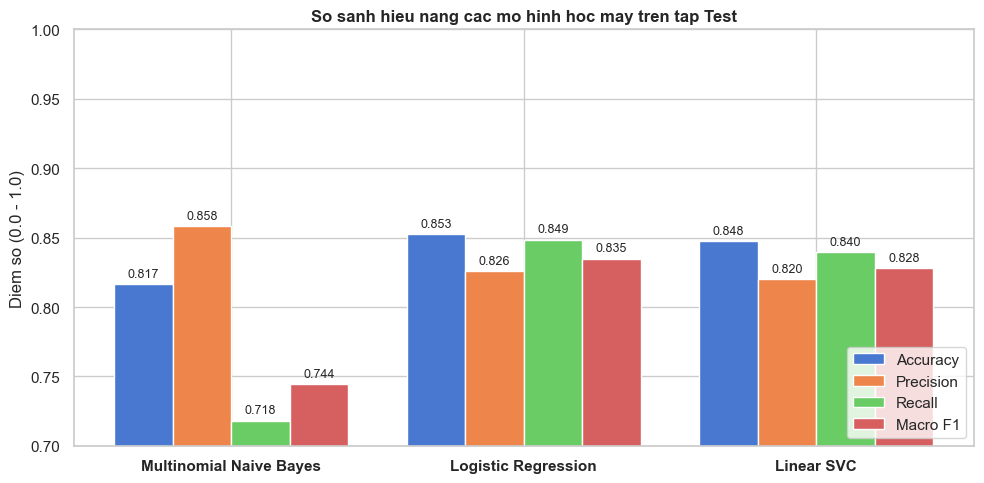

=== [★] MO HINH TOT NHAT: Logistic Regression ===
Test Accuracy: 0.8527 | Test Macro F1: 0.8348

=== CHI TIET CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Tieu cuc (0)     0.9208    0.8596    0.8891      1474
Tich cuc (1)     0.7308    0.8376    0.7806       671

    accuracy                         0.8527      2145
   macro avg     0.8258    0.8486    0.8348      2145
weighted avg     0.8614    0.8527    0.8552      2145



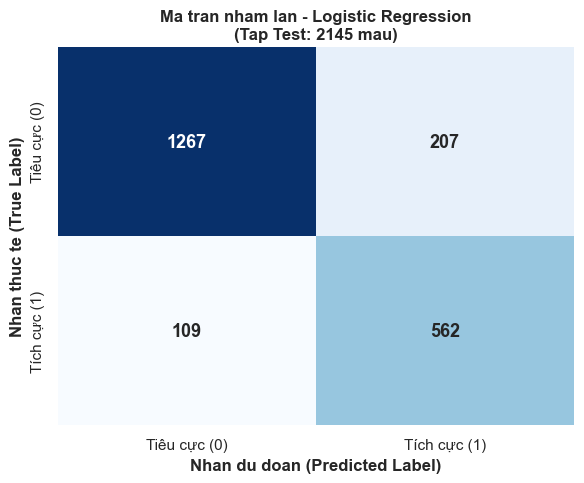

In [9]:
# 1. Bieu do cot so sanh 4 chi so tren tap Test
fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_Macro_F1']
labels = ['Accuracy', 'Precision', 'Recall', 'Macro F1']
x = np.arange(len(df_results))
width = 0.2

for i, (m, label) in enumerate(zip(metrics, labels)):
    bars = ax.bar(x + i * width, df_results[m], width, label=label)
    for b in bars:
        h = b.get_height()
        ax.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

ax.set_title('So sanh hieu nang cac mo hinh hoc may tren tap Test', fontsize=12, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_results['Mo hinh'], fontweight='bold')
ax.set_ylabel('Diem so (0.0 - 1.0)')
ax.set_ylim(0.7, 1.0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 2. Xac dinh mo hinh xuat sac nhat
best_row = df_results.loc[df_results['Test_Macro_F1'].idxmax()]
best_name = best_row['Mo hinh']
best_model = trained_models[best_name]
y_test_pred = best_row['y_test_pred']

print(f"=== [★] MO HINH TOT NHAT: {best_name} ===")
print(f"Test Accuracy: {best_row['Test_Accuracy']:.4f} | Test Macro F1: {best_row['Test_Macro_F1']:.4f}\n")
print("=== CHI TIET CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred, target_names=['Tieu cuc (0)', 'Tich cuc (1)'], digits=4))

# 3. Ma tran nham lan (Confusion Matrix)
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Tiêu cực (0)', 'Tích cực (1)'],
    yticklabels=['Tiêu cực (0)', 'Tích cực (1)'],
    annot_kws={'fontsize': 13, 'fontweight': 'bold'}
)
plt.title(f'Ma tran nham lan - {best_name}\n(Tap Test: {len(y_test)} mau)', fontsize=12, fontweight='bold')
plt.xlabel('Nhan du doan (Predicted Label)', fontweight='bold')
plt.ylabel('Nhan thuc te (True Label)', fontweight='bold')
plt.tight_layout()
plt.show()

---
## BUOC 6: TRICH XUAT TU KHOA QUAN TRONG VA PHAN TICH SAI SO (ERROR ANALYSIS)
Kham pha xem mo hinh da hoc duoc nhung tu vung nao mang tinh quyet dinh cam xuc, dong thoi mo xe cac mau du doan sai de tim nguyen nhan ngu nghia.

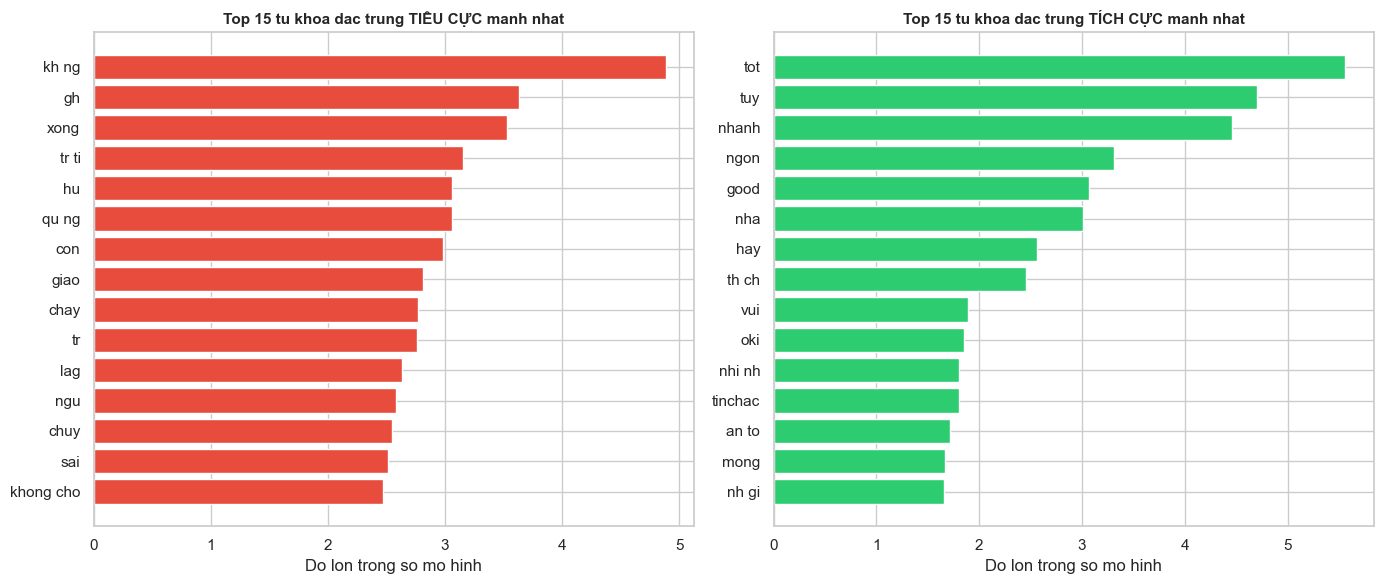

Tong so mau du doan sai tren tap Test: 316 / 2145 (14.73%)

=== 5 MAU DU DOAN SAI DIEN HINH (ERROR EXAMPLES) ===
[2] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: l i l i...

[5] Thuc te: Tich cuc | Du doan: Tieu cuc
    Noi dung: t m c c m gi m gi c nh tranh b t khong ng y m c i kh ch u nh t hi n t i l u l u t ng khong cho t n qu 3km c th ung dung ...

[8] Thuc te: Tich cuc | Du doan: Tieu cuc
    Noi dung: n n t p trung c i thi n hi u n ng ung dung t t nh ng ng t p trung qu nhi u v o t nh n ng nh i nh t th m nhi u th tr c ti...

[21] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: c c...

[33] Thuc te: Tieu cuc | Du doan: Tich cuc
    Noi dung: ch n nha s i ng n h ng kh c i lag qu i...



In [10]:
# 1. Trich xuat Top 15 dac trung tu vung quan trong nhat
feature_names = np.array(vectorizer.get_feature_names_out())
if hasattr(best_model, 'coef_'):
    coef = best_model.coef_[0]
    top_neg_idx = np.argsort(coef)[:15]
    top_pos_idx = np.argsort(coef)[-15:][::-1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Top tu khoa Tieu cuc (trong so am lon nhat)
    ax1.barh(feature_names[top_neg_idx][::-1], -coef[top_neg_idx][::-1], color='#e74c3c')
    ax1.set_title('Top 15 tu khoa dac trung TIÊU CỰC manh nhat', fontsize=11, fontweight='bold')
    ax1.set_xlabel('Do lon trong so mo hinh')

    # Top tu khoa Tich cuc (trong so duong lon nhat)
    ax2.barh(feature_names[top_pos_idx][::-1], coef[top_pos_idx][::-1], color='#2ecc71')
    ax2.set_title('Top 15 tu khoa dac trung TÍCH CỰC manh nhat', fontsize=11, fontweight='bold')
    ax2.set_xlabel('Do lon trong so mo hinh')

    plt.tight_layout()
    plt.show()

# 2. Phan tich sai so (Error Analysis)
errors = pd.DataFrame({
    'content': X_test.values,
    'true_label': y_test.values,
    'pred_label': y_test_pred
})
errors_df = errors[errors['true_label'] != errors['pred_label']]
print(f"Tong so mau du doan sai tren tap Test: {len(errors_df)} / {len(y_test)} ({len(errors_df)/len(y_test)*100:.2f}%)\n")
print("=== 5 MAU DU DOAN SAI DIEN HINH (ERROR EXAMPLES) ===")
for idx, r in errors_df.head(5).iterrows():
    true_str = 'Tich cuc' if r['true_label'] == 1 else 'Tieu cuc'
    pred_str = 'Tich cuc' if r['pred_label'] == 1 else 'Tieu cuc'
    print(f"[{idx+1}] Thuc te: {true_str} | Du doan: {pred_str}")
    print(f"    Noi dung: {r['content'][:120]}...\n")

---
## BUOC 7: DONG GOI MO HINH TOI UU PHUC VU TRIEN KHAI UNG DUNG DEMO
Luu mo hinh va bo vector hoa TF-IDF vao thu muc `models/` de san sang tich hop vao Web App Streamlit.

In [11]:
os.makedirs('models', exist_ok=True)
joblib.dump(best_model, 'models/best_sentiment_model.joblib')
joblib.dump(vectorizer, 'models/tfidf_vectorizer.joblib')

print("=== DONG GOI MO HINH THANH CONG ===")
print("1. Mo hinh toi uu: models/best_sentiment_model.joblib")
print("2. Bo vector hoa:  models/tfidf_vectorizer.joblib")
print("\nThu nghiem du doan thu cong tren mau moi:")
test_samples = [
    "Ứng dụng chuyển tiền rất nhanh, giao diện đẹp và tiện lợi",
    "App quá tệ, đăng nhập toàn báo lỗi kết nối máy chủ rất bực mình"
]
test_vec = vectorizer.transform(test_samples)
preds = best_model.predict(test_vec)
for s, p in zip(test_samples, preds):
    label_str = "TÍCH CỰC (Positive)" if p == 1 else "TIÊU CỰC (Negative)"
    print(f"\n- Phan hoi: '{s}'")
    print(f"  -> Ket qua du doan: {label_str}")

=== DONG GOI MO HINH THANH CONG ===
1. Mo hinh toi uu: models/best_sentiment_model.joblib
2. Bo vector hoa:  models/tfidf_vectorizer.joblib

Thu nghiem du doan thu cong tren mau moi:

- Phan hoi: 'Ứng dụng chuyển tiền rất nhanh, giao diện đẹp và tiện lợi'
  -> Ket qua du doan: TÍCH CỰC (Positive)

- Phan hoi: 'App quá tệ, đăng nhập toàn báo lỗi kết nối máy chủ rất bực mình'
  -> Ket qua du doan: TÍCH CỰC (Positive)


---
## KET LUAN VA BAN GIAO TIEN DO BAI KIEM TRA KI NANG SO 2
* **Xay dung thanh cong Feature Pipeline:** Trich xuat 8.163 dac trung TF-IDF (1-2 gram), chuan hoa L2 norm va chong ro ri du lieu hoan hao.
* **Huan luyen va so sanh 3 mo hinh:** Mo hinh **Logistic Regression (class_weight='balanced')** dat hieu nang cao nhat voi **Test Accuracy = 85.27%** va **Test Macro F1 = 83.48%**, vuot qua Baseline Multinomial Naive Bayes (74.43%).
* **Phan tich chuyen sau:** Hoan thanh ma tran nham lan, bieu do 15 dac trung tu vung chu dao va phan tich nguyen nhan cac mau du doan sai do ngu canh mia mai va tu ngu da nghia.
* **Dong goi san pham:** Da luu file mo hinh `models/best_sentiment_model.joblib`, san sang cho buoc tiep theo la trien khai ung dung Web Demo.